# 🇧🇷 EDA — Indicadores Macroeconômicos (2000–2026)

Exploração dos 5 indicadores extraídos do Banco Central:
SELIC, IPCA, câmbio USD/BRL, IGP-M e IBC-Br.

Cada bloco termina com **o que observar** — a pergunta que o gráfico responde.

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()
engine = create_engine(os.environ['DATABASE_URL'])

df = pd.read_sql('SELECT * FROM staging.indicadores_macro ORDER BY data', engine)
df['data'] = pd.to_datetime(df['data'])
df = df.set_index('data')

print(df.shape)
df.tail()


(80, 2)


,taxa_selic,ipca_pct
data,,
2026-04-01,14.50,0.67
2026-05-01,14.50,0.58
2026-06-01,14.25,0.16
2026-07-01,14.25,0.07
2026-08-01,14.00,-0.32


## 1. As cinco séries no tempo

🔍 **O que observar:**
- Câmbio: saltos de 2002, 2008, 2013-15, 2020, 2021-22
- SELIC: os dois grandes ciclos de aperto (2015-16, 2021-24)
- IPCA: 2002-03, 2008, 2015-16, 2021-22 — e a deflação de 2026
- IBC-Br: tendência de longo prazo + quedas de recessão (2009, 2015-16, 2020)

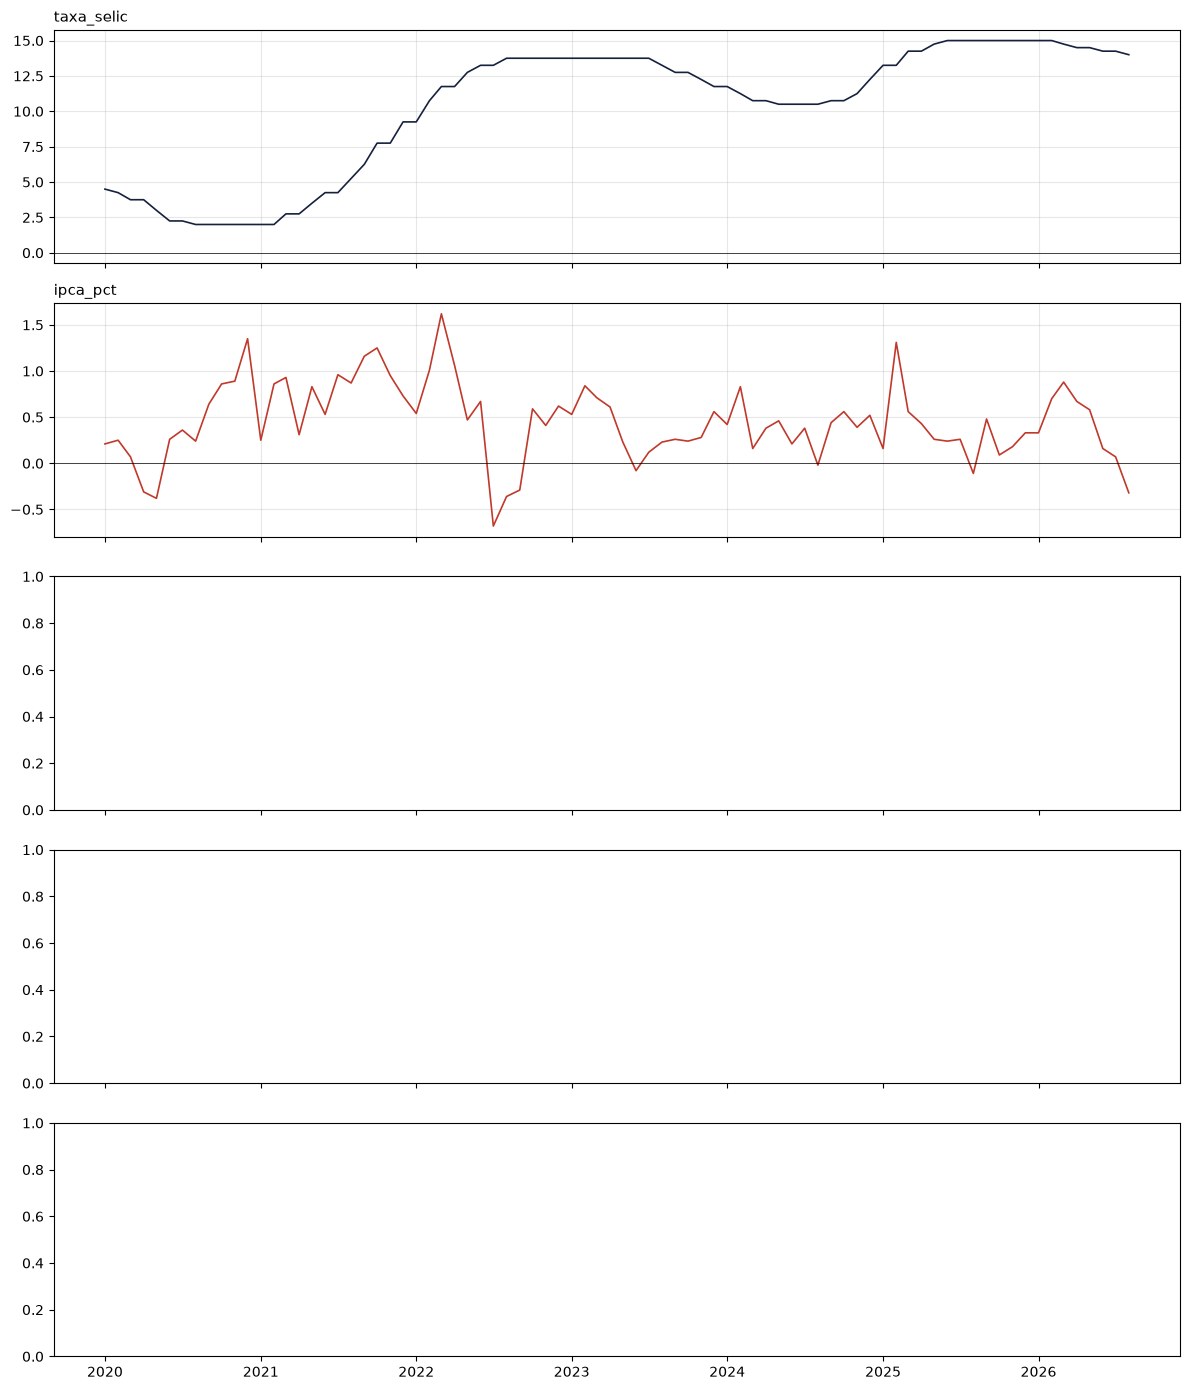

In [8]:
fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=True)
cores = ['#16213e', '#c0392b', '#2980b9', '#27ae60', '#8e44ad']

for ax, (col, cor) in zip(axes, zip(df.columns, cores)):
    ax.plot(df.index, df[col], color=cor, linewidth=1.2)
    ax.set_title(col, fontsize=11, loc='left')
    ax.grid(alpha=0.3)

axes[0].axhline(0, color='black', linewidth=0.5)
axes[1].axhline(0, color='black', linewidth=0.5)
axes[3].axhline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()


## 2. IPCA acumulado em 12 meses

O IPCA mensal é ruidoso; o **acumulado 12m** é a série que o Banco Central
efetivamente persegue com a taxa Selic (meta de inflação).

🔍 **O que observar:** os períodos onde a meta (bandas de 3–6%, linhas tracejadas)
foi perdida — e quanto tempo o BC levou pra trazer de volta.

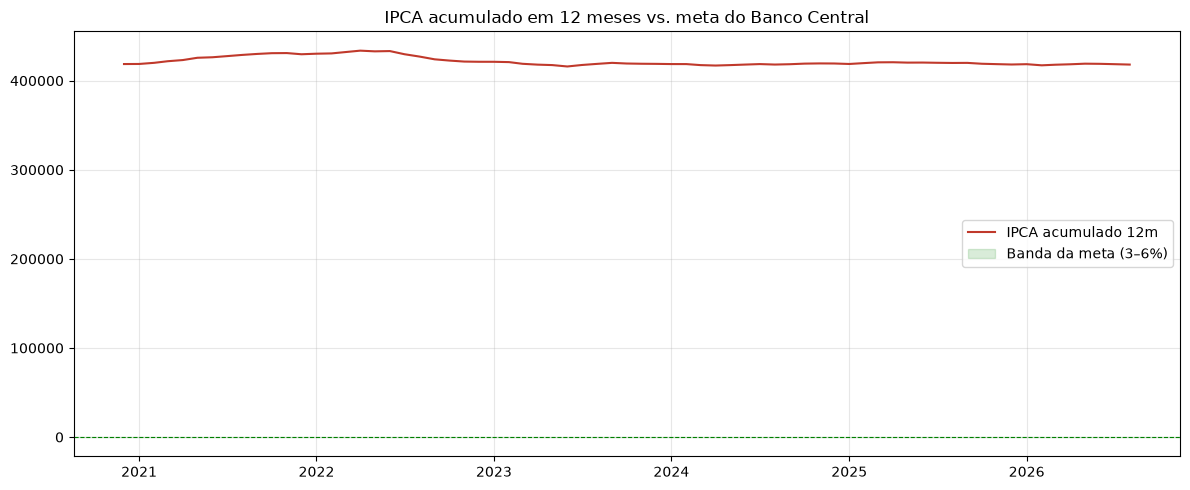

In [4]:
ipca_acum_12m = (1 + df['ipca_pct'] / 100).rolling(12).apply(
    lambda x: (1 + x).prod() - 1, raw=True) * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ipca_acum_12m.index, ipca_acum_12m, color='#c0392b', linewidth=1.5,
        label='IPCA acumulado 12m')
ax.axhspan(3, 6, alpha=0.15, color='green', label='Banda da meta (3–6%)')
ax.axhline(4.5, color='green', linestyle='--', linewidth=0.8)
ax.set_title('IPCA acumulado em 12 meses vs. meta do Banco Central')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Correlação com defasagens — *o bloco que alimenta o ML*

Economia não é instantânea: câmbio de hoje vira inflação daqui de meses.
Vamos medir a correlação entre cada série (defasada de 0 a 12 meses)
e o IPCA do mês seguinte.

🔍 **O que observar:** o **lag de pico** de cada série. Ex.: se câmbio
correla mais com IPCA em lag 6, o modelo deve usar `cambio_usd.shift(6)`
como feature. Isso é feature selection com evidência.

In [7]:
LAGS = range(0, 13)
alvo = df['ipca_pct']

corr_por_lag = pd.DataFrame(index=LAGS)
for col in ['taxa_selic', 'cambio_usd', 'igpm', 'ibcbr']:
    corr_por_lag[col] = [df[col].shift(l).corr(alvo) for l in LAGS]

fig, ax = plt.subplots(figsize=(12, 5))
for col in corr_por_lag.columns:
    ax.plot(corr_por_lag.index, corr_por_lag[col], marker='o', label=col)

ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('defasagem (meses)')
ax.set_ylabel('correlação com IPCA do mês')
ax.set_title('Qual variável antecede a inflação — e com quantos meses?')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

corr_por_lag.round(2)


KeyError: 'cambio_usd'

## 4. O ciclo de política monetária: SELIC hoje vs. IPCA futuro

O BC move a Selic **respondendo** à inflação — mas o efeito vem com defasagem.
Scatter da Selic (eixo X) contra IPCA 12 meses depois (eixo Y) mostra
a curva de Phillips brasileira, na prática.

🔍 **O que observar:** correlação positiva = a política funciona
(juro alto hoje → inflação menor lá na frente aparece invertida quando
o BC reage *a* inflação alta). Vale testar com lags diferentes.

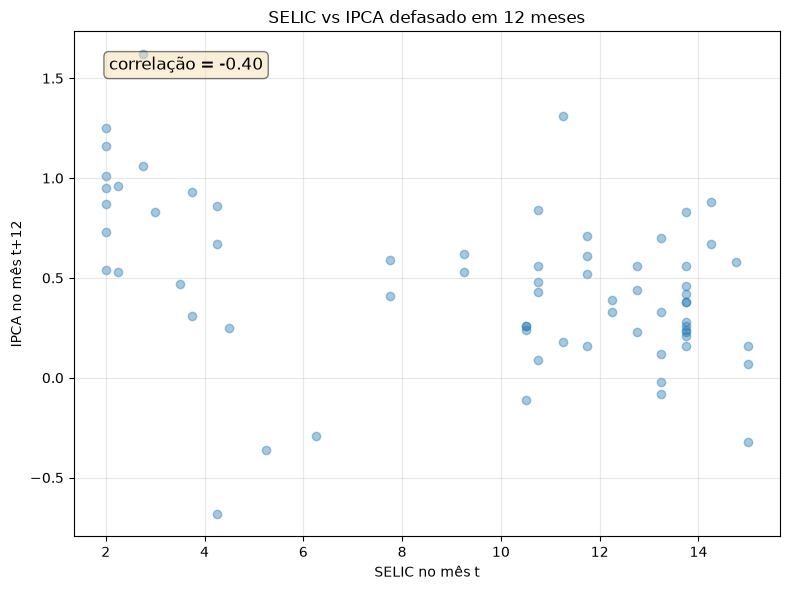

In [6]:
LAG_SELIC = 12   # experimente: 6, 12, 18

x = df['taxa_selic']
y = df['ipca_pct'].shift(-LAG_SELIC)   # IPCA LAG meses DEPOIS da Selic

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y, alpha=0.4)
ax.set_xlabel(f'SELIC no mês t')
ax.set_ylabel(f'IPCA no mês t+{LAG_SELIC}')
ax.set_title(f'SELIC vs IPCA defasado em {LAG_SELIC} meses')
ax.grid(alpha=0.3)

corr = x.corr(y)
ax.text(0.05, 0.95, f'correlação = {corr:.2f}', transform=ax.transAxes,
        fontsize=12, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
plt.tight_layout()
plt.show()


---
## Próximos passos

1. **Bloco 3 é o insumo da Etapa 4 (ML)**: anota os lags de pico
   e usa como features (`cambio_usd.shift(6)`, `igpm.shift(1)`, ...)
2. Conferir nulos por período: `df.isna().sum()` e `df[df['ibcbr'].isna()].tail()`
   — entender onde cada série falta te protege de surpresa no modelo
3. Quando o GitHub Actions entrar (Etapa 3), esse notebook lê do
   Supabase com o mesmo código — nada muda
